<a href="https://colab.research.google.com/github/Shivamthakur7500/FireWatchNet/blob/main/04_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

#*Load integrated data*

In [ ]:
PROJECT_DIR = Path("/content/drive/MyDrive/FireWatchNet")

integrated_path = (
    PROJECT_DIR
    / "Data/processed/Integrated/FireWatchNet_Integrated_2023_2024.csv"
)

data = pd.read_csv(integrated_path)

data["date"] = pd.to_datetime(data["date"])

print("Shape:", data.shape)
display(data.head())

Shape: (731, 7)


,date,temperature_2m,total_precipitation_sum,volumetric_soil_water_layer_1,wind_speed,fire_count,fire_label
0,2023-01-01,276.014916,0.001051,0.256939,0.342874,739,1
1,2023-01-02,275.179416,0.000877,0.258764,0.402984,852,1
2,2023-01-03,273.853810,0.000710,0.261232,0.523513,788,1
3,2023-01-04,274.099017,0.000009,0.261558,0.829598,883,1
4,2023-01-05,274.884068,0.000002,0.260220,0.932673,862,1


In [ ]:
data["temperature_c"] = data["temperature_2m"] - 273.15
data["precipitation_mm"] = data["total_precipitation_sum"] * 1000


#*Check fire-label balance*

fire_label
0    370
1    361
Name: count, dtype: int64


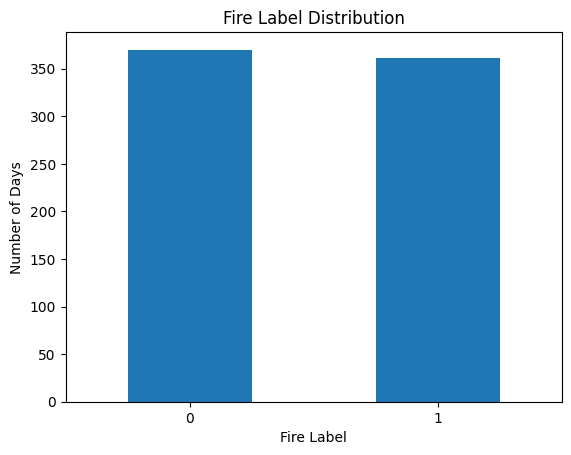

In [ ]:
print(data["fire_label"].value_counts())

data["fire_label"].value_counts().plot(
    kind="bar",
    title="Fire Label Distribution"
)

plt.xlabel("Fire Label")
plt.ylabel("Number of Days")
plt.xticks(rotation=0)
plt.show()

#*Plot daily fire counts*

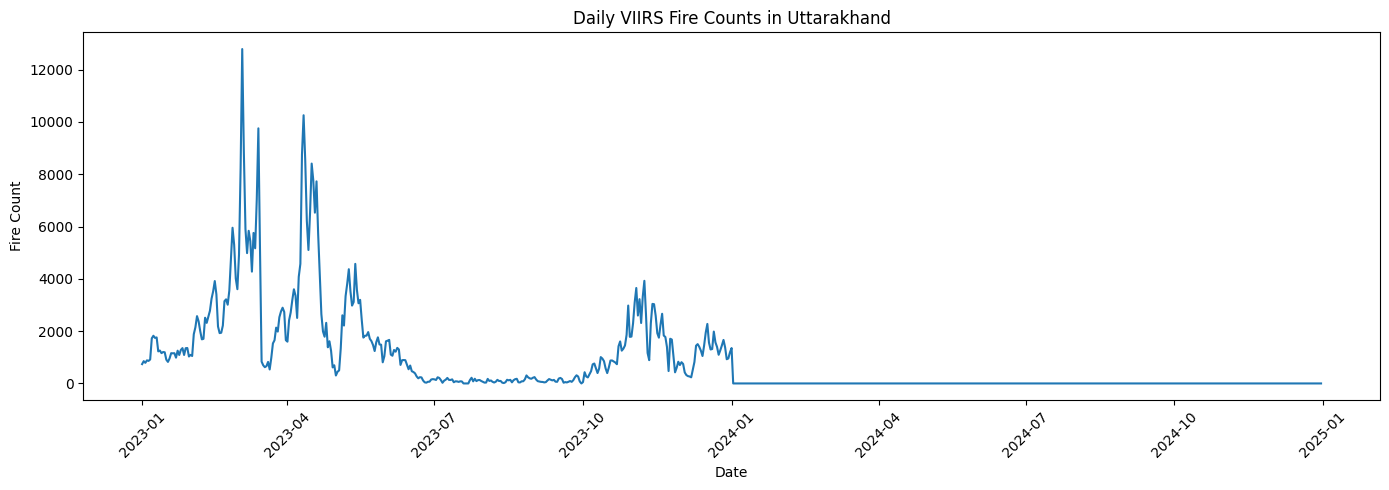

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    data["date"],
    data["fire_count"]
)

plt.title("Daily VIIRS Fire Counts in Uttarakhand")
plt.xlabel("Date")
plt.ylabel("Fire Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#*Plot weather variables*

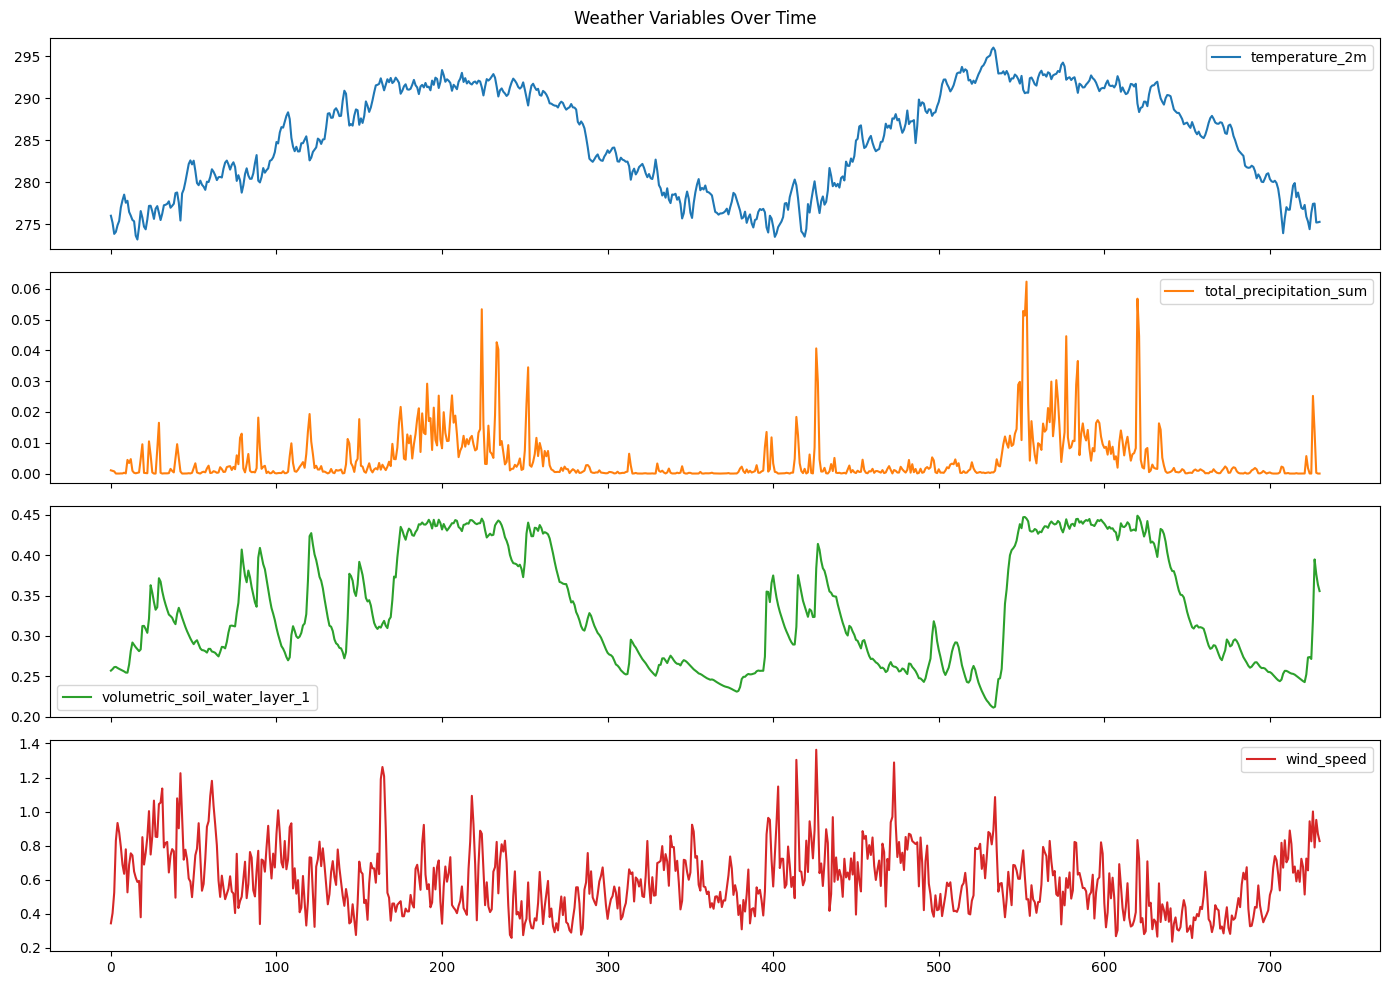

In [ ]:
weather_columns = [
    "temperature_2m",
    "total_precipitation_sum",
    "volumetric_soil_water_layer_1",
    "wind_speed"
]

data[weather_columns].plot(
    subplots=True,
    figsize=(14, 10),
    title="Weather Variables Over Time"
)

plt.tight_layout()
plt.show()

#*Correlation matrix*

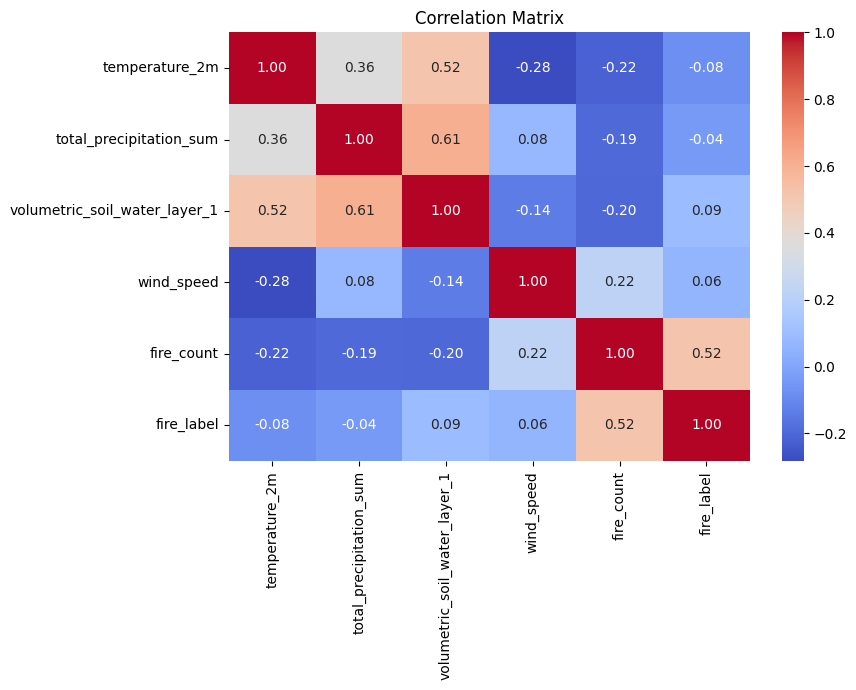

In [ ]:
correlation_columns = [
    "temperature_2m",
    "total_precipitation_sum",
    "volumetric_soil_water_layer_1",
    "wind_speed",
    "fire_count",
    "fire_label"
]

correlation_matrix = data[correlation_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

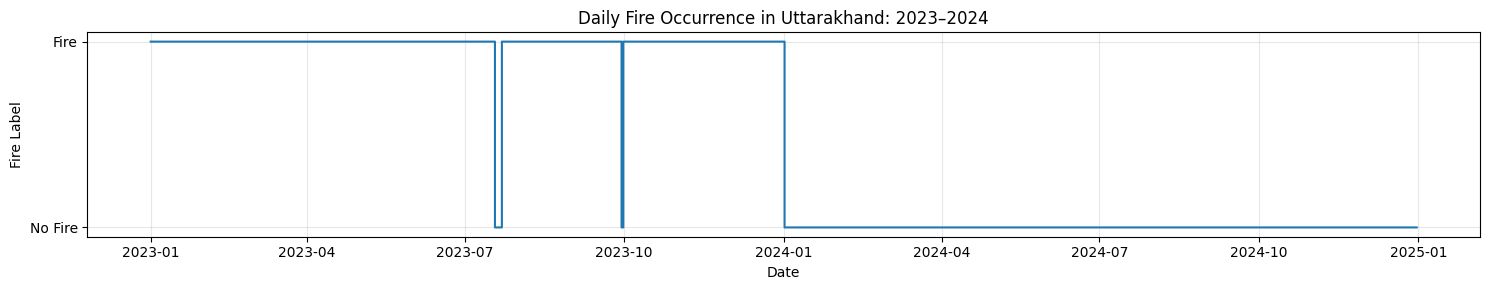

In [ ]:
plt.figure(figsize=(15, 3))

plt.step(
    data["date"],
    data["fire_label"],
    where="mid"
)

plt.title("Daily Fire Occurrence in Uttarakhand: 2023–2024")
plt.xlabel("Date")
plt.ylabel("Fire Label")
plt.yticks([0, 1], ["No Fire", "Fire"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
weather_comparison = data.groupby("fire_label")[
    [
        "temperature_2m",
        "total_precipitation_sum",
        "volumetric_soil_water_layer_1",
        "wind_speed"
    ]
].mean()

weather_comparison.index = ["No Fire", "Fire"]

display(weather_comparison)

,temperature_2m,total_precipitation_sum,volumetric_soil_water_layer_1,wind_speed
No Fire,285.652486,0.004854,0.325743,0.584889
Fire,284.669376,0.004200,0.338258,0.608006


#*Compare weather on fire and non-fire days*

In [ ]:
display(
    data.groupby("fire_label")[weather_columns].mean()
)

,temperature_2m,total_precipitation_sum,volumetric_soil_water_layer_1,wind_speed
fire_label,,,,
0,285.652486,0.004854,0.325743,0.584889
1,284.669376,0.004200,0.338258,0.608006


#*Save EDA summary*

In [ ]:
eda_summary = data.groupby("fire_label")[weather_columns].mean()

summary_path = (
    PROJECT_DIR
    / "results/EDA_weather_fire_summary.csv"
)

summary_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

eda_summary.to_csv(summary_path)

print("Saved:", summary_path)

Saved: /content/drive/MyDrive/FireWatchNet/results/EDA_weather_fire_summary.csv


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = df[
    [
        "temperature_2m",
        "total_precipitation_sum",
        "volumetric_soil_water_layer_1",
        "wind_speed",
        "fire_label"
    ]
].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Weather Features and Fire Label")
plt.show()

NameError: name 'df' is not defined